In [63]:
import os
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sympy import rotations

plt.style.use("Solarize_Light2")
sns.set_style("whitegrid")
plt.figure(figsize=(20,6))

%matplotlib inline

<Figure size 2000x600 with 0 Axes>

In [64]:
def get_missing_dates(series, start_date=None, end_date=None, freq='D'):
    """
    :param series: 需要检查的时间序列
    :param start_date: 生成时间序列的开始时间
    :param end_date: 生成时间序列的结束时间
    :param freq: 生成时间序列的间隔
    :return:
    """
    if start_date is None:
        start_date = series.min()
    if end_date is None:
        end_date = series.max()

    return pd.date_range(start_date, end_date, freq=freq).difference(series)


def check_duplicate(df, subset=None):
    """
    :param df: 需要检查的数据集
    :param subset: 分组变量
    :return:
    """
    if subset is not None:
        return df.duplicated(subset=subset, keep=False).sum()
    else:
        return df.duplicated(keep=False).sum()


def check_null(df):
    """
    :param df: 数据集
    :return:
    """
    return df.isnull().sum()


def create_date_features(df, date):
    """
    构造日期特征
    :param df: 数据集
    :param date: 日期名称
    :return:
    """
    temp = df.copy()

    temp.loc[:, 'year'] = df.loc[:, date].dt.year
    temp.loc[:, 'month'] = df.loc[:, date].dt.month
    temp.loc[:, 'day'] = df.loc[:, date].dt.day
    temp.loc[:, 'hour'] = df.loc[:, date].dt.hour

    temp.loc[:, 'quarter'] = df.loc[:, date].dt.quarter
    temp.loc[:, 'week_of_year'] = df.loc[:, date].dt.isocalendar().week
    temp.loc[:, 'dayofweek'] = df.loc[:, date].dt.dayofweek
    temp.loc[:, 'dayofyear'] = df.loc[:, date].dt.dayofyear

    temp.loc[:, 'is_month_start'] = df.loc[:, date].dt.is_month_start
    temp.loc[:, 'is_month_end'] = df.loc[:, date].dt.is_month_end
    temp.loc[:, 'is_quarter_start'] = df.loc[:, date].dt.is_quarter_start
    temp.loc[:, 'is_quarter_end'] = df.loc[:, date].dt.is_quarter_end
    temp.loc[:, 'is_year_start'] = df.loc[:, date].dt.is_year_start
    temp.loc[:, 'is_year_end'] = df.loc[:, date].dt.is_year_end

    temp.loc[:, 'month_year'] = df.loc[:, date].dt.to_period('M')

    return temp



In [65]:
# 加载数据集
DATA_DIR = "./datasets"

telemetry_df = pd.read_csv(f"{DATA_DIR}/PdM_telemetry.csv",)
errors_df = pd.read_csv(f"{DATA_DIR}/PdM_errors.csv")
maint_df = pd.read_csv(f"{DATA_DIR}/PdM_maint.csv")
failures_df = pd.read_csv(f"{DATA_DIR}/PdM_failures.csv")
machines_df = pd.read_csv(f"{DATA_DIR}/PdM_machines.csv")

In [66]:
# 统一转换时间序列，并且按照时间进行排序
tables = [telemetry_df, maint_df, failures_df, errors_df]
for df in tables:
    df["datetime"] = pd.to_datetime(df["datetime"], format="%Y-%m-%d %H:%M:%S")
    df.sort_values(['datetime', 'machineID'], inplace=True, ignore_index=True)

# Telemetry Data

In [67]:
# 数据集描述
telemetry_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 876100 entries, 0 to 876099
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   datetime   876100 non-null  datetime64[us]
 1   machineID  876100 non-null  int64         
 2   volt       876100 non-null  float64       
 3   rotate     876100 non-null  float64       
 4   pressure   876100 non-null  float64       
 5   vibration  876100 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 40.1 MB


In [68]:
# 数据采集日期
telemetry_df["datetime"].describe()

count                 876100
mean     2015-07-02 18:00:00
min      2015-01-01 06:00:00
25%      2015-04-02 12:00:00
50%      2015-07-02 18:00:00
75%      2015-10-02 00:00:00
max      2016-01-01 06:00:00
Name: datetime, dtype: object

数据分布时间：2015-07-02~2016-01-01 \
数据采集频率：小时

In [69]:
# 检查是连续采集的日期、时间是否存在缺失
get_missing_dates(telemetry_df['datetime'],
                  freq='h')

DatetimeIndex([], dtype='datetime64[us]', freq='h')

In [70]:
# 检查重复的记录
check_duplicate(telemetry_df, ['datetime', 'machineID'])

np.int64(0)

In [71]:
# 检查存在缺失值的记录
check_null(telemetry_df)

datetime     0
machineID    0
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

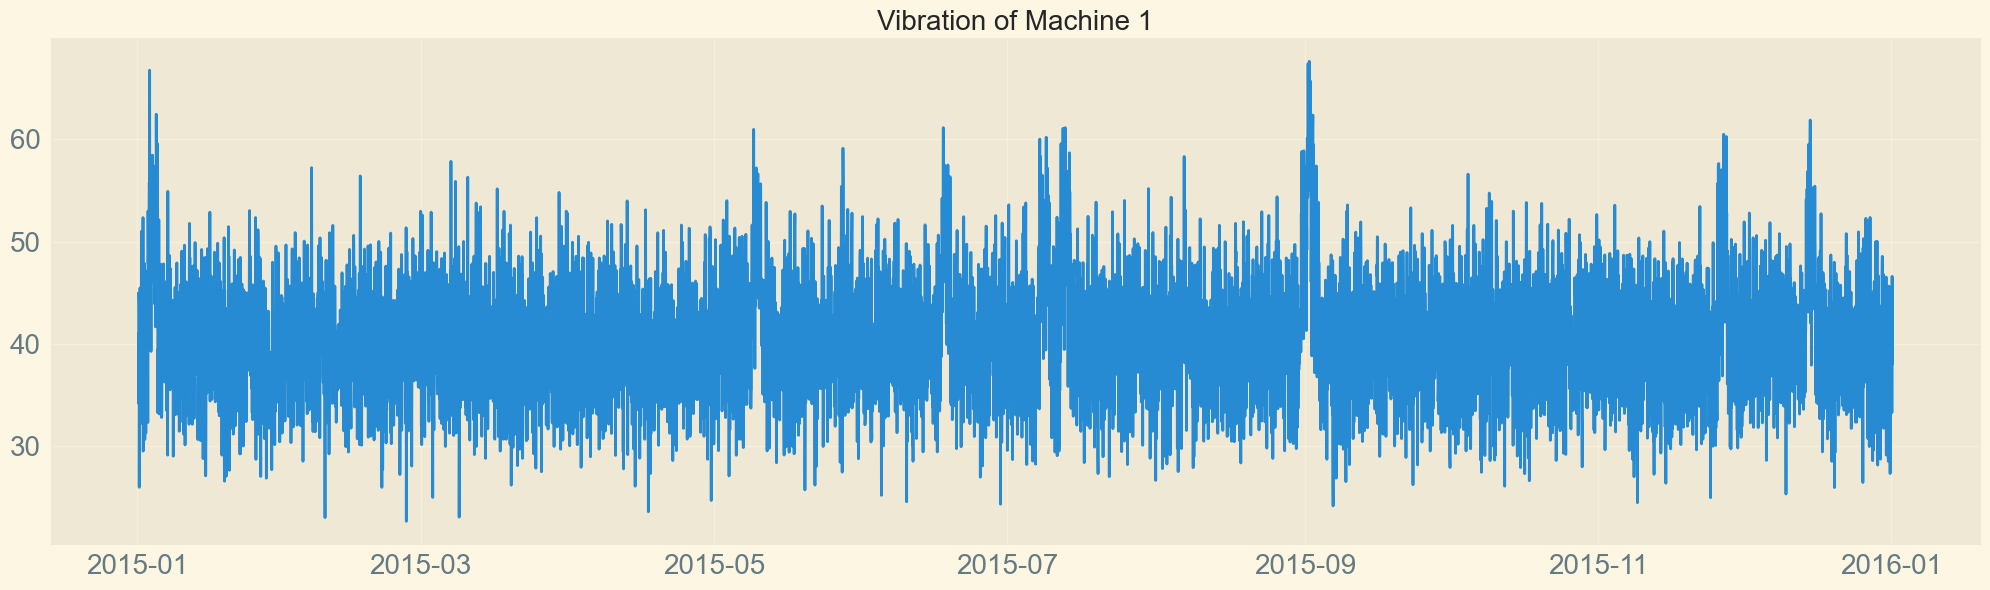

In [72]:
plt.style.use("Solarize_Light2")

# 1号机器的vibration分布图
df_vib_machine_1 = telemetry_df[telemetry_df['machineID'] == 1][['datetime', 'vibration']].set_index('datetime')

plt.figure(figsize=(20, 6))
plt.plot(df_vib_machine_1, )
plt.title('Vibration of Machine 1',
          fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()

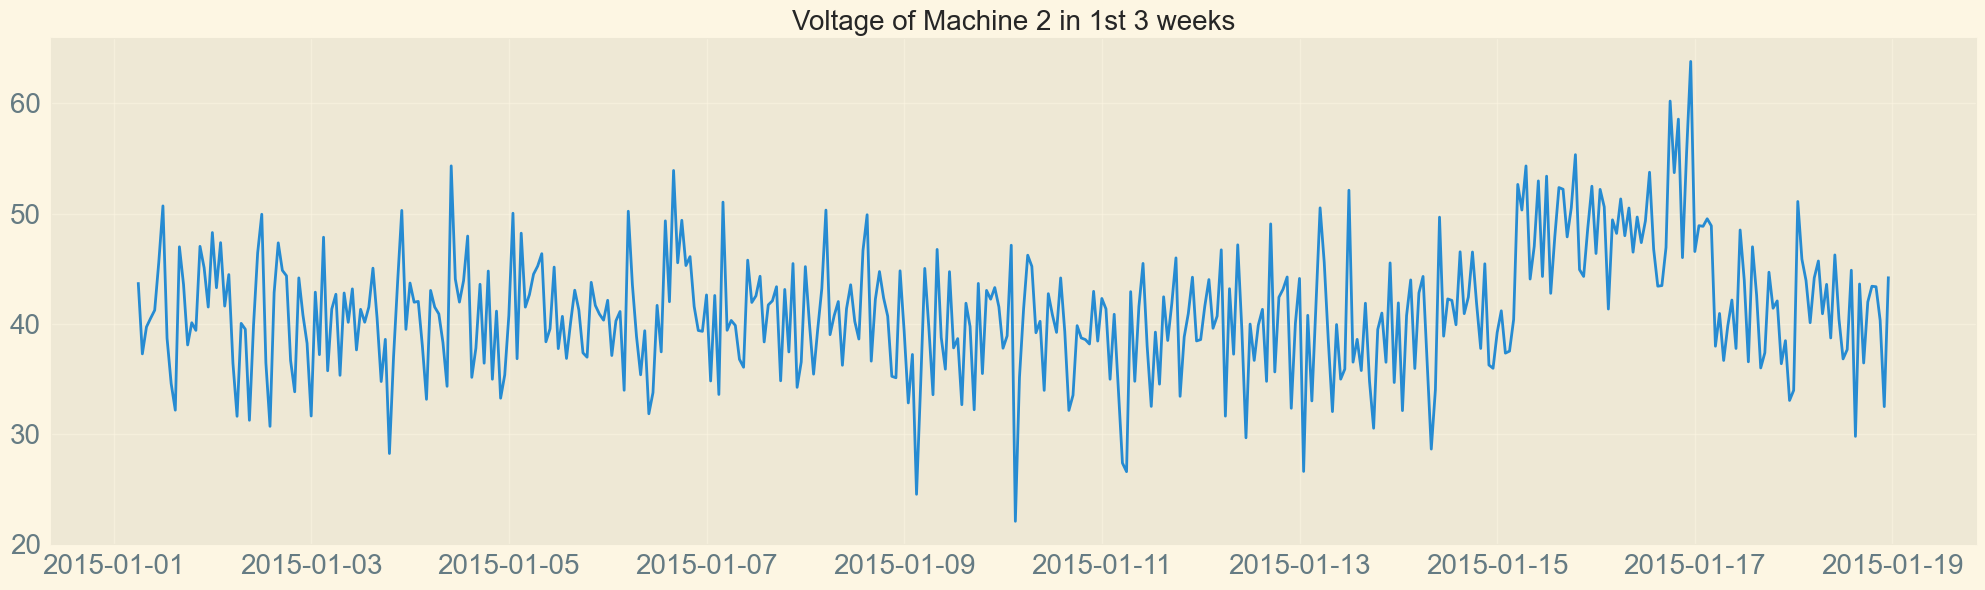

In [73]:
# 2号机器前两周的电压分布图
df_volt_machine_2 = (telemetry_df[(telemetry_df['machineID'] == 2)
                                  & (telemetry_df['datetime'].dt  # 访问datetime属性
                                     .isocalendar()['week'].isin([1, 2, 3]))]  # 取ISO日历（ISO年，ISO周数，ISO星期几）第二个属性
                     [['datetime', 'vibration']]
                     .set_index('datetime'))
plt.figure(figsize=(20, 6))
plt.plot(df_volt_machine_2)
plt.title('Voltage of Machine 2 in 1st 3 weeks',
          fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()

In [74]:
# 构造日期特征
telemetry_df = create_date_features(df=telemetry_df, date='datetime')
telemetry_df.head()

,datetime,machineID,volt,rotate,pressure,vibration,year,month,day,hour,...,week_of_year,dayofweek,dayofyear,is_month_start,is_month_end,is_quarter_start,is_quarter_end,is_year_start,is_year_end,month_year
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,2015,1,1,6,...,1,3,1,True,False,True,False,True,False,2015-01
1,2015-01-01 06:00:00,2,176.558913,424.624162,76.005332,43.767049,2015,1,1,6,...,1,3,1,True,False,True,False,True,False,2015-01
2,2015-01-01 06:00:00,3,185.482043,461.211137,87.453199,28.216864,2015,1,1,6,...,1,3,1,True,False,True,False,True,False,2015-01
3,2015-01-01 06:00:00,4,169.710847,463.646727,95.929877,38.400372,2015,1,1,6,...,1,3,1,True,False,True,False,True,False,2015-01
4,2015-01-01 06:00:00,5,165.082899,452.283576,84.591722,40.298803,2015,1,1,6,...,1,3,1,True,False,True,False,True,False,2015-01


<Figure size 2000x600 with 0 Axes>

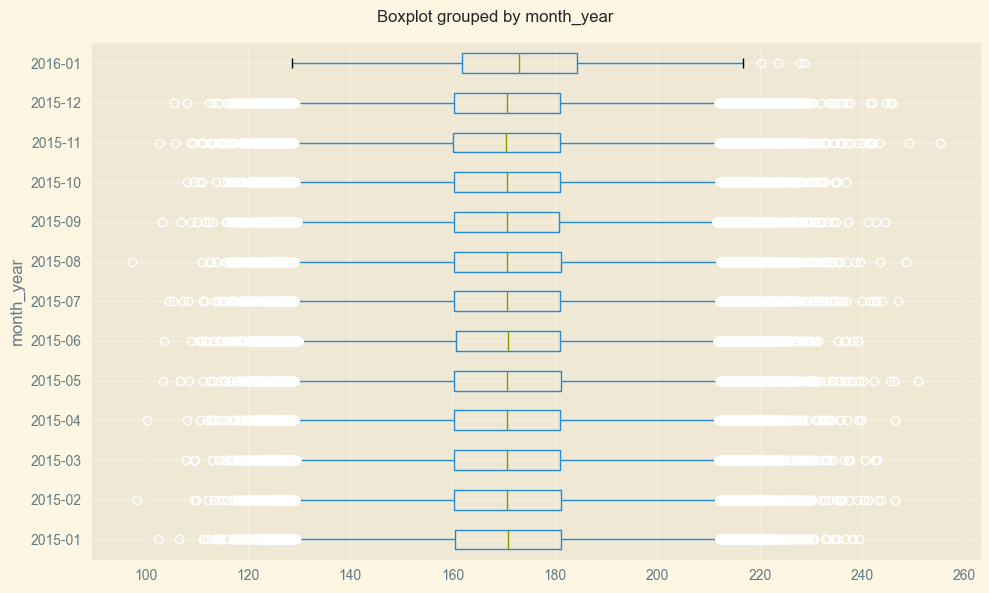

In [75]:
# 电压数据的箱型图
plt.figure(figsize=(20, 6))
telemetry_df.boxplot(column='volt',
                by='month_year',
                vert=False,
                figsize=(10, 6),)
plt.title('')
plt.tight_layout()
plt.show()

每月的电压并没有显著波动

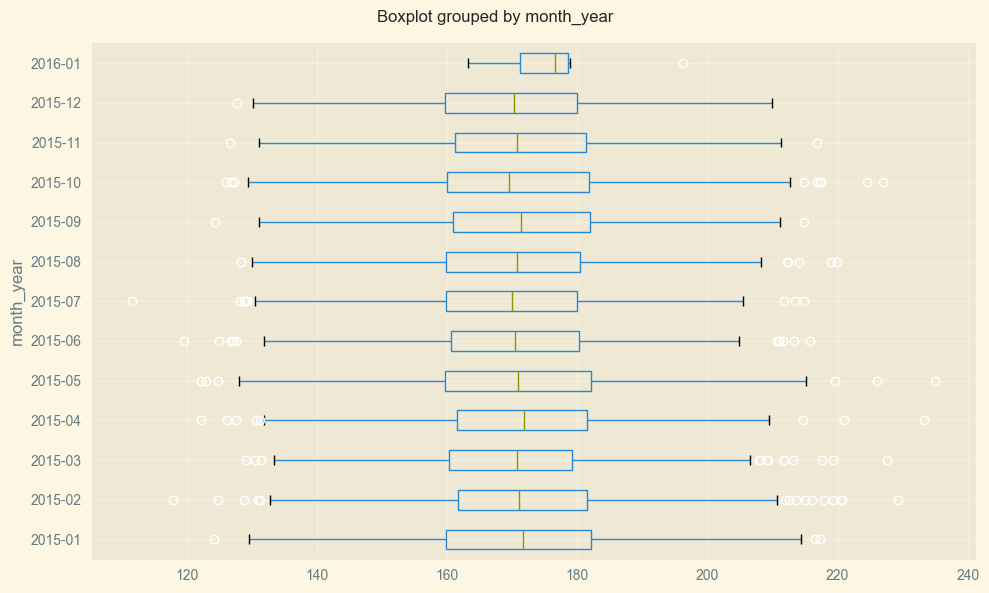

In [76]:
plt.style.use("Solarize_Light2")
df = telemetry_df[telemetry_df['machineID'] == 42]
df.boxplot(column='volt',
                by='month_year',
                vert=False,
                figsize=(10, 6),)
plt.title('')
plt.tight_layout()
plt.show()

对于随机某台机器，月份间的电压波动不明显

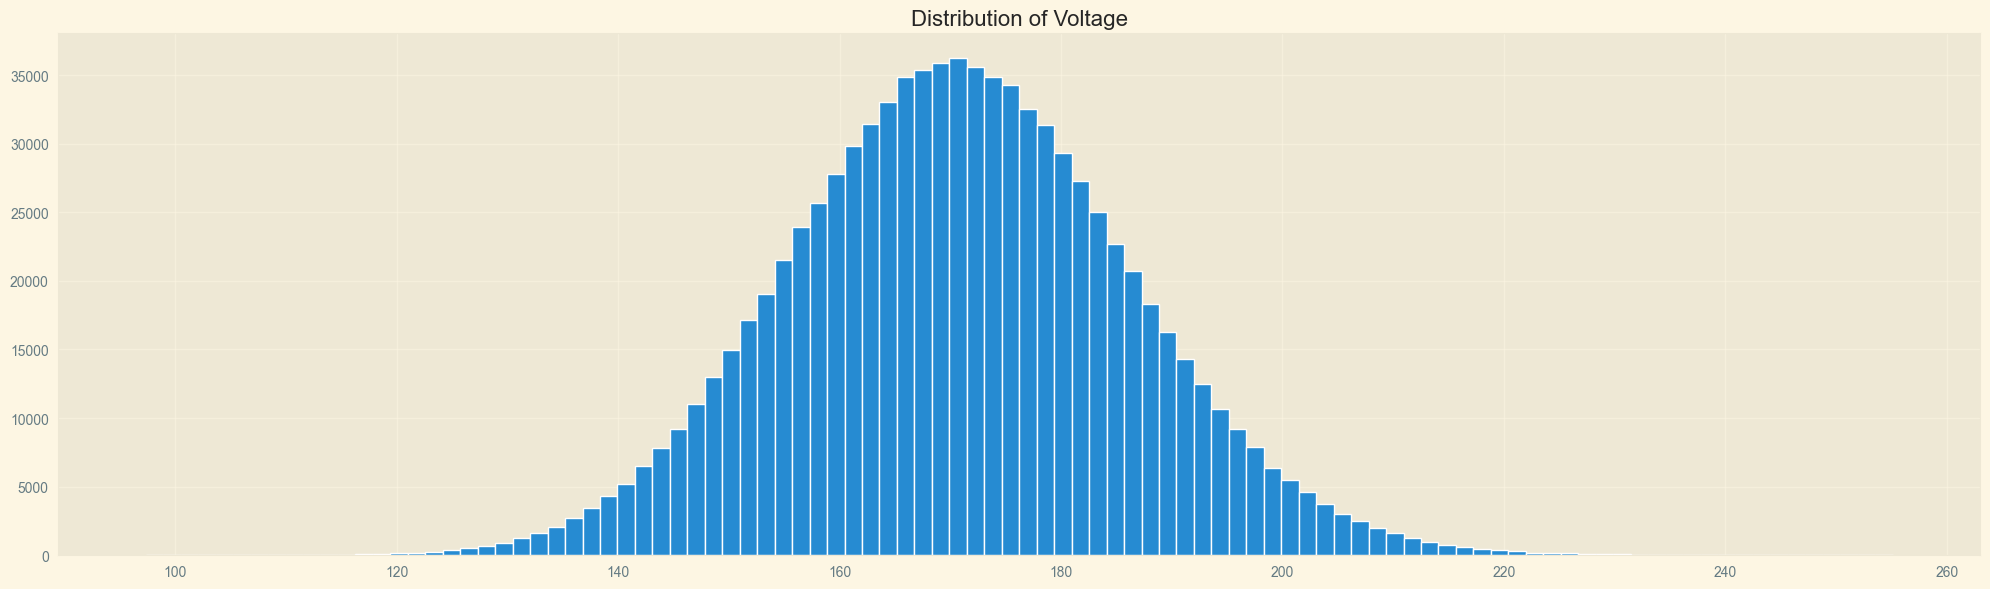

In [77]:
plt.figure(figsize=(20, 6))
plt.hist(telemetry_df['volt'],
         bins=100)
plt.title('Distribution of Voltage')
plt.tight_layout()
plt.show()

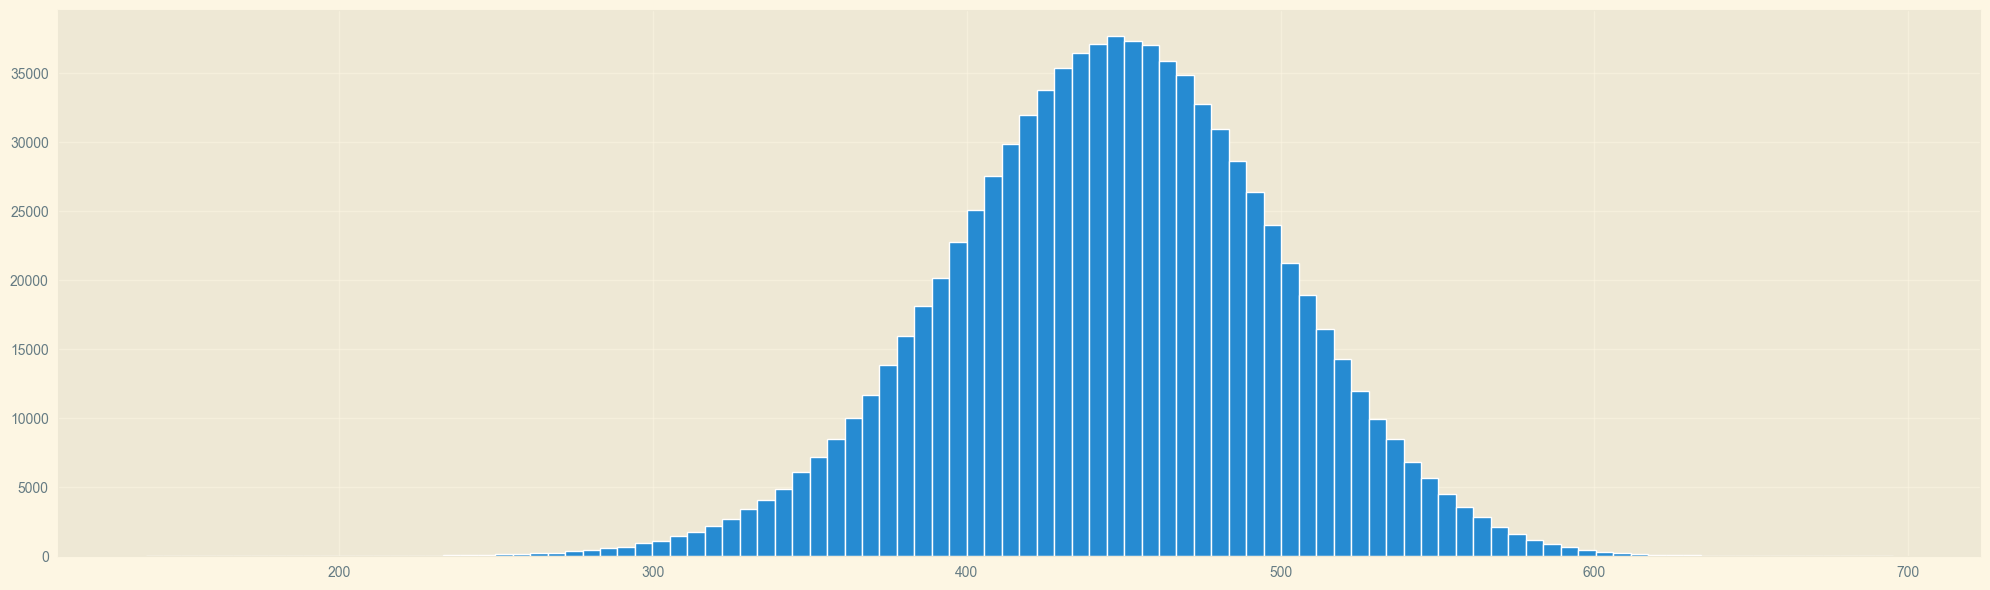

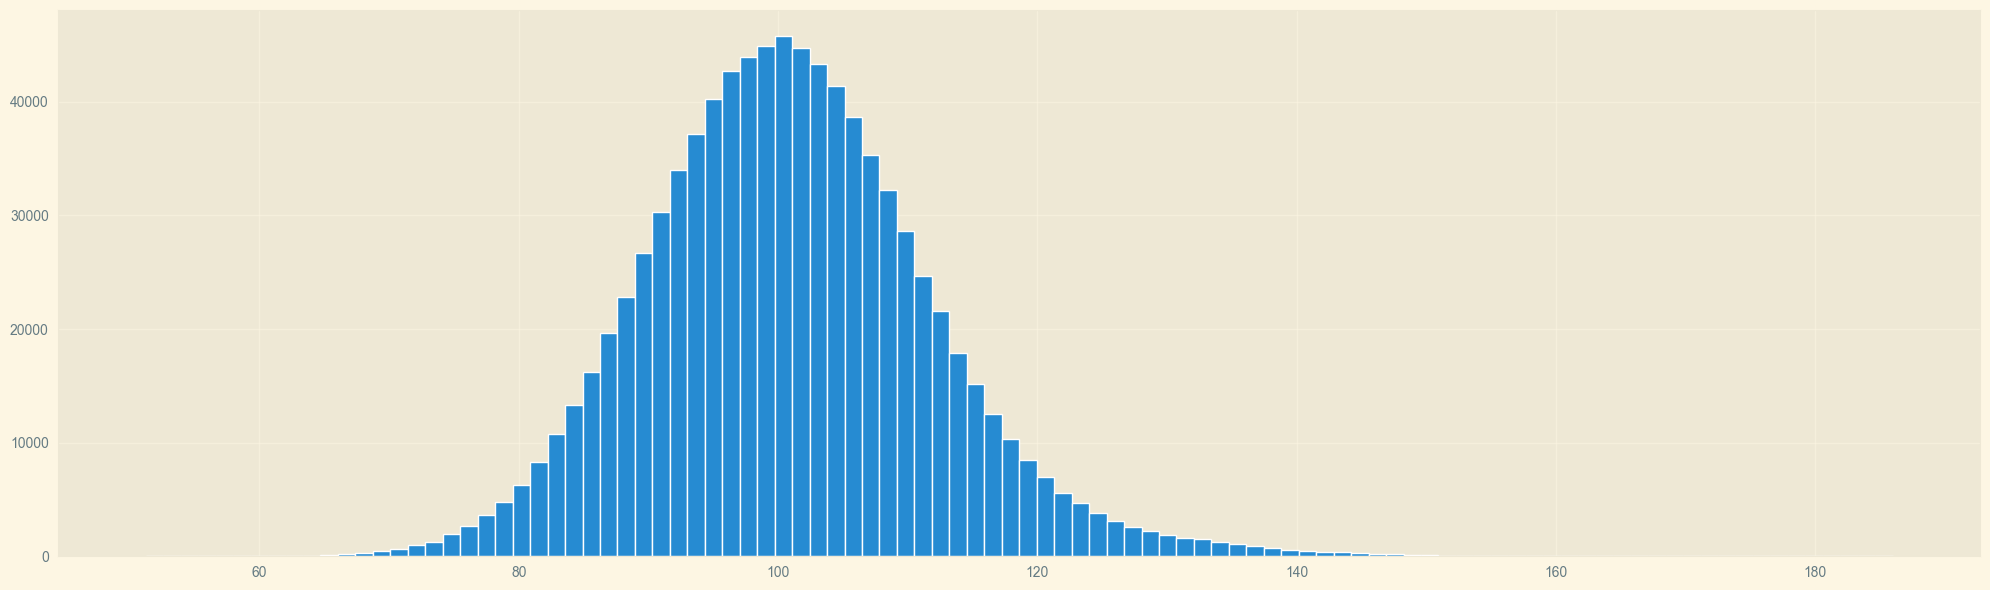

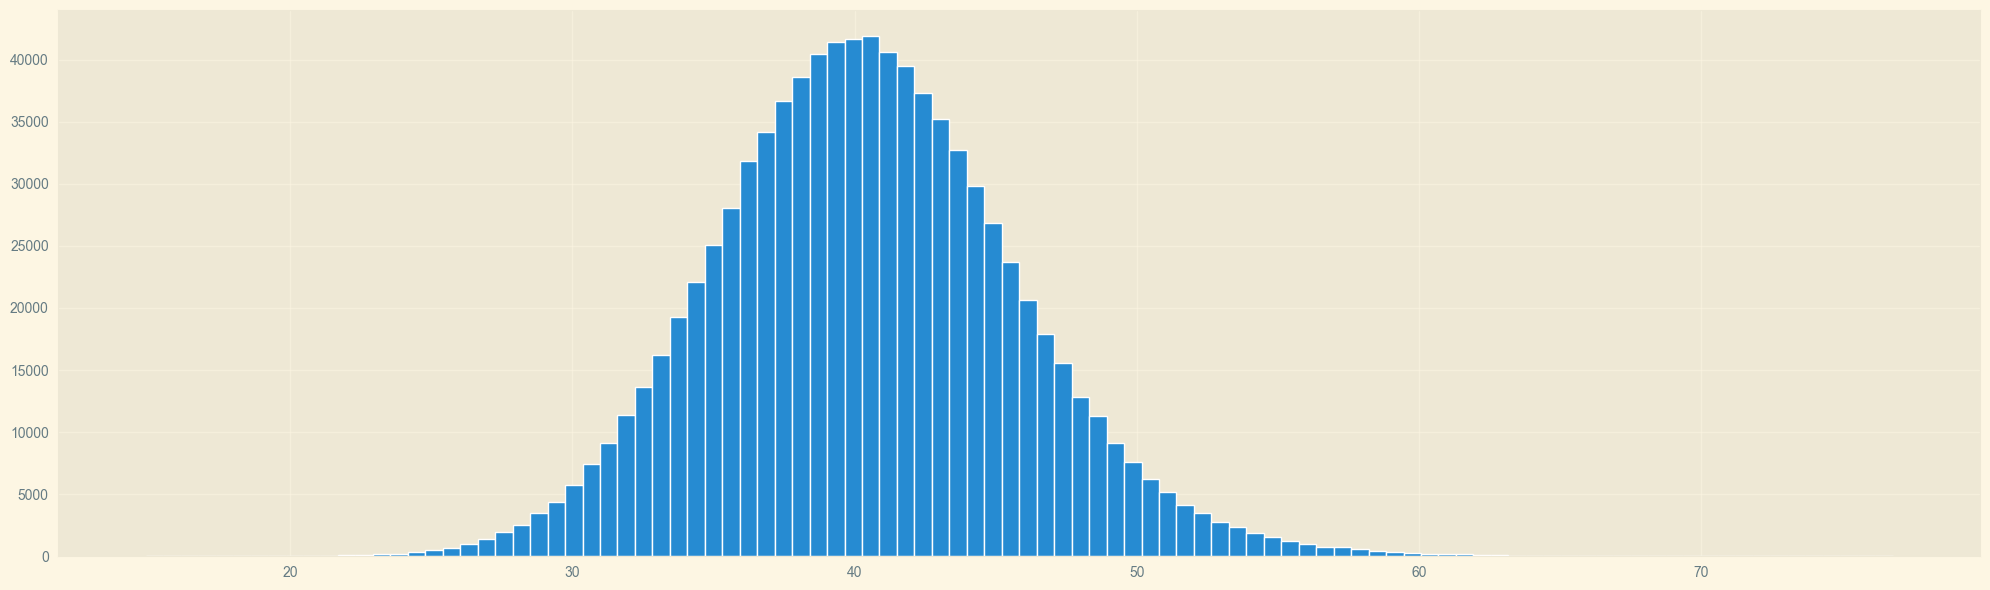

In [78]:
for name in ['rotate', 'pressure', 'vibration']:
    plt.figure(figsize=(20, 6))
    plt.hist(telemetry_df[name],
             bins=100)
    plt.tight_layout()
    plt.show()

# Error Data

In [84]:
errors_df['machineID'] = errors_df['machineID'].astype('category')
errors_df['errorID'] = errors_df['errorID'].astype('category')
print(errors_df.info())
print(errors_df.head())

<class 'pandas.DataFrame'>
RangeIndex: 3919 entries, 0 to 3918
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   datetime   3919 non-null   datetime64[us]
 1   machineID  3919 non-null   category      
 2   errorID    3919 non-null   category      
dtypes: category(2), datetime64[us](1)
memory usage: 39.2 KB
None
             datetime machineID errorID
0 2015-01-01 06:00:00        24  error1
1 2015-01-01 06:00:00        73  error4
2 2015-01-01 06:00:00        81  error1
3 2015-01-01 07:00:00        43  error3
4 2015-01-01 08:00:00        14  error4


In [85]:
# 排序
errors_df = errors_df.sort_values(['datetime', 'machineID'], ignore_index=True)
errors_df.head()

,datetime,machineID,errorID
0,2015-01-01 06:00:00,24,error1
1,2015-01-01 06:00:00,73,error4
2,2015-01-01 06:00:00,81,error1
3,2015-01-01 07:00:00,43,error3
4,2015-01-01 08:00:00,14,error4


In [90]:
# 查重
num = errors_df.duplicated(keep=False).sum()
print(num)

0


In [92]:
# 查缺
errors_df.isnull().sum()

datetime     0
machineID    0
errorID      0
dtype: int64

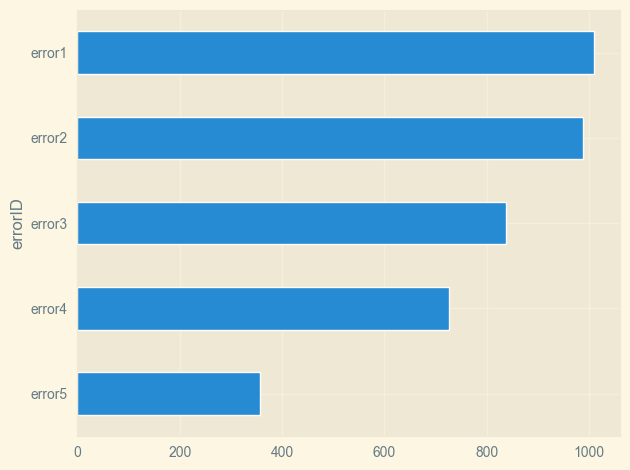

In [106]:
errors_df['errorID'].value_counts().sort_values().plot(kind='barh')
plt.tight_layout()
plt.show()

CategoricalIndex(['error1', 'error2', 'error3', 'error4', 'error5'], categories=['error1', 'error2', 'error3', 'error4', 'error5'], ordered=False, dtype='category', name='errorID')